In [8]:
import re
import pandas as pd
from collections import defaultdict
import os

# Function to extract data from the structure info file and group by space group
def extract_structure_data(file_path, functional_name, grouped_data, energy_data):
    with open(file_path, 'r') as file:
        data = file.read()

    # Split data by separators
    phases = data.split('-----------------------------------------')

    for phase in phases:
        # Extract space group, lattice constants, angles, and energy (E0)
        space_group_match = re.search(r'International:\s*(\S+)', phase)
        lattice_constants_match = re.search(r'Lattice Constants:\s*([\d\.]+\s+[\d\.]+\s+[\d\.]+)', phase)
        lattice_angles_match = re.search(r'Lattice Angles:\s*([\d\.]+\s+[\d\.]+\s+[\d\.]+)', phase)
        energy_match = re.search(r'E0=\s*([-\d\.E+]+)', phase)

        if space_group_match and lattice_constants_match and lattice_angles_match and energy_match:
            space_group = space_group_match.group(1)
            lattice_constants = list(map(float, lattice_constants_match.group(1).split()))
            lattice_angles = list(map(float, lattice_angles_match.group(1).split()))
            energy = float(energy_match.group(1))

            if space_group not in grouped_data:
                grouped_data[space_group] = defaultdict(lambda: [float('nan')] * 6)

            grouped_data[space_group][functional_name] = lattice_constants + lattice_angles

            if space_group not in energy_data:
                energy_data[space_group] = defaultdict(lambda: float('nan'))

            energy_data[space_group][functional_name] = energy

# Function to save the grouped data into a CSV file for lattice constants and angles
def save_to_csv(file_paths, output_structure_csv, output_energy_csv="different_partial_doping_energy_data.csv"):
    grouped_data = defaultdict(lambda: defaultdict(list))
    energy_data = defaultdict(lambda: defaultdict(float))

    # Extract data from each file
    for file_path, functional_name in file_paths:
        extract_structure_data(file_path, functional_name, grouped_data, energy_data)

    # --- 关键修改 1: 定义所需的列排序 ---
    desired_order = ['HfO2', 'a-HZO', 'b-HZO', 'c-HZO']
    # 获取实际存在的所有 functional
    avail_functionals = list(set([func for _, func in file_paths]))
    
    # 按照 desired_order 排序，如果在 desired_order 里找不到的，就放到最后
    sorted_functionals = [f for f in desired_order if f in avail_functionals]
    sorted_functionals += [f for f in avail_functionals if f not in desired_order]

    ### ----- STRUCTURE DATA -----
    # Load existing structure data if file exists
    if os.path.exists(output_structure_csv):
        existing_df = pd.read_csv(output_structure_csv)
    else:
        existing_df = pd.DataFrame()

    all_data = []
    for space_group, func_data in grouped_data.items():
        row = {'Space Group': space_group}
        for func in sorted_functionals:
            values = func_data.get(func, [float('nan')] * 6)
            for val, label in zip(values, ['a', 'b', 'c', 'alpha', 'beta', 'gamma']):
                row[f"{func} {label}"] = val
        all_data.append(row)

    new_df = pd.DataFrame(all_data)

    # Merge logic (保留之前的 KeyError 修复)
    if not existing_df.empty:
        # 删除 existing_df 中即将被更新的列，避免 _x, _y 后缀
        cols_to_update = [c for c in new_df.columns if c != 'Space Group']
        existing_df = existing_df.drop(columns=[c for c in cols_to_update if c in existing_df.columns])
        merged_df = pd.merge(existing_df, new_df, on="Space Group", how="outer")
    else:
        merged_df = new_df

    # --- 关键修改 2: 强制按照指定顺序重排 Structure 文件的列 ---
    final_cols_order = ['Space Group']
    for func in sorted_functionals:
        for label in ['a', 'b', 'c', 'alpha', 'beta', 'gamma']:
            col_name = f"{func} {label}"
            if col_name in merged_df.columns:
                final_cols_order.append(col_name)
    
    # 添加可能存在的、但不在我们排序列表中的其他列（防止数据丢失）
    remaining_cols = [c for c in merged_df.columns if c not in final_cols_order]
    merged_df = merged_df[final_cols_order + remaining_cols]

    merged_df.to_csv(output_structure_csv, index=False)

    ### ----- ENERGY DATA -----
    if os.path.exists(output_energy_csv):
        energy_df_existing = pd.read_csv(output_energy_csv)
        existing_energies = energy_df_existing.set_index("Space Group").to_dict("index")
    else:
        existing_energies = {}

    energy_rows = {}
    for space_group, func_energies in energy_data.items():
        row = {"Space Group": space_group}
        for func in sorted_functionals:
            row[f"{func} Energy"] = func_energies.get(func, float('nan'))
        energy_rows[space_group] = row

    # Update with existing data
    for sg, row in existing_energies.items():
        if sg not in energy_rows:
            energy_rows[sg] = {"Space Group": sg}
        energy_rows[sg].update(row)

    energy_df = pd.DataFrame(list(energy_rows.values()))

    # --- 关键修改 3: 使用 P2_1/c 作为能量参考基准 ---
    reference_phase = "Pca2_1"
    
    for func in sorted_functionals:
        col = f"{func} Energy"
        if col in energy_df.columns:
            # 尝试找到 P2_1/c 对应的能量值
            ref_row = energy_df.loc[energy_df["Space Group"] == reference_phase, col]
            
            if not ref_row.empty and pd.notna(ref_row.values[0]):
                ref_energy = ref_row.values[0]
                print(f"Reference energy for {func}: {ref_energy} (Phase: {reference_phase})")
                energy_df[col] = energy_df[col] - ref_energy
            else:
                # 如果找不到 P2_1/c，退回到使用最小能量，或者你可以选择不减
                min_energy = energy_df[col].min()
                print(f"Warning: {reference_phase} not found for {func}. Using min energy {min_energy} as ref.")
                energy_df[col] = energy_df[col] - min_energy

    # --- 关键修改 4: 强制按照指定顺序重排 Energy 文件的列 ---
    energy_cols_order = ['Space Group']
    for func in sorted_functionals:
        col_name = f"{func} Energy"
        if col_name in energy_df.columns:
            energy_cols_order.append(col_name)
            
    # 添加剩余列
    remaining_energy_cols = [c for c in energy_df.columns if c not in energy_cols_order]
    energy_df = energy_df[energy_cols_order + remaining_energy_cols]

    # 可选：按第一个 functional 的能量值对行进行排序
    first_col = f"{sorted_functionals[0]} Energy"
    if first_col in energy_df.columns:
        energy_df = energy_df.sort_values(by=first_col)

    energy_df.to_csv(output_energy_csv, index=False)

# 请确保文件路径正确
file_paths = [
    ('HfO2-pbe-structure_info.txt', 'HfO2'),
    ('a-HZO-structure_info.txt', 'a-HZO'),
    ('b-HZO-structure_info.txt', 'b-HZO'),
    ('c-HZO-structure_info.txt', 'c-HZO')
]

save_to_csv(file_paths, 'repair_different_partial_doping_structure_data_grouped_.csv')

Reference energy for HfO2: 0.0 (Phase: Pca2_1)
Reference energy for a-HZO: 0.0 (Phase: Pca2_1)
Reference energy for b-HZO: 0.0 (Phase: Pca2_1)
Reference energy for c-HZO: 0.0 (Phase: Pca2_1)


Plot saved to comparison_bar_chart_corrected.png


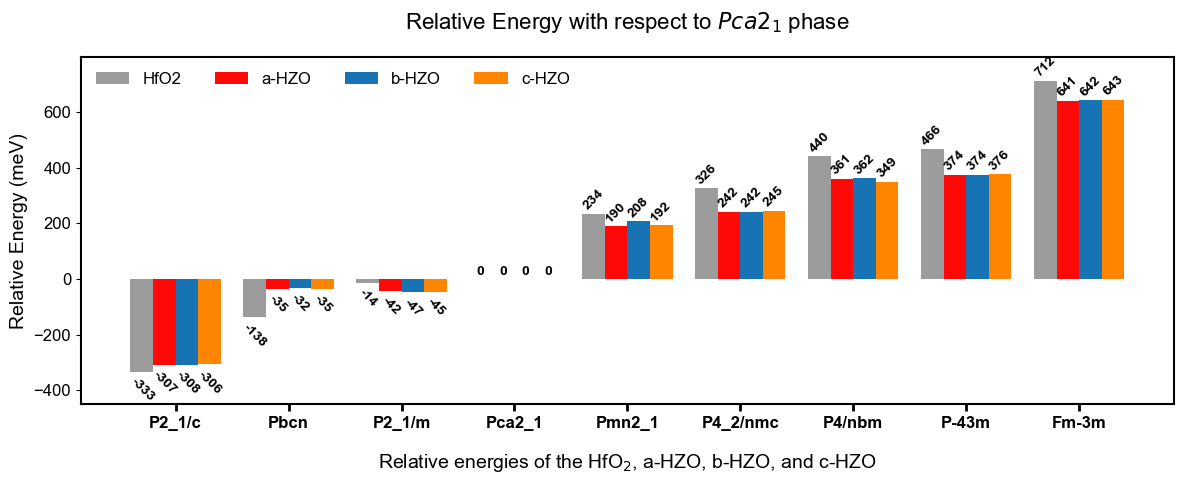

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib

# 设置全局字体
matplotlib.rcParams['font.family'] = 'Arial'

def plot_comparison_bar_chart(csv_file):
    """
    Reads the CSV file and plots a grouped bar chart with specific colors and order.
    """
    # 1. 读取数据
    try:
        data = pd.read_csv(csv_file)
    except FileNotFoundError:
        print(f"Error: File {csv_file} not found.")
        return

    # 2. 定义绘图的顺序、对应的列名、图例标签和颜色
    # 顺序：HfO2 -> a-HZO -> b-HZO -> c-HZO
    plot_config = [
        {'col': 'HfO2 Energy',   'label': 'HfO2',  'color': '#9c9c9c'},
        {'col': 'a-HZO Energy',  'label': 'a-HZO', 'color': '#ff0808'},
        {'col': 'b-HZO Energy',  'label': 'b-HZO', 'color': '#1873b5'},
        {'col': 'c-HZO Energy',  'label': 'c-HZO', 'color': '#ff8400'}
    ]

    phases = data['Space Group']
    x = np.arange(len(phases))
    
    # 设置柱状图宽度
    total_width = 0.8       # 一组柱子的总宽度
    n_bars = len(plot_config)
    bar_width = total_width / n_bars
    
    fig, ax = plt.subplots(figsize=(12, 5))

    # 3. 循环绘制柱状图
    # 计算偏移量，使得一组柱子整体居中
    # 比如4个柱子，偏移量索引应该是 -1.5, -0.5, 0.5, 1.5
    
    bars_list = []
    
    for i, config in enumerate(plot_config):
        col_name = config['col']
        
        # 检查列是否存在
        if col_name not in data.columns:
            print(f"Warning: Column '{col_name}' not found in CSV. Filling with 0.")
            y_values = np.zeros(len(phases))
        else:
            # 单位转换：eV -> meV
            y_values = data[col_name] * 1000

        # 计算当前柱子的 x 坐标
        # i - (n_bars - 1) / 2  => 将索引 0,1,2,3 映射为 -1.5, -0.5, 0.5, 1.5
        offset = (i - (n_bars - 1) / 2) * bar_width
        
        bar = ax.bar(
            x + offset, 
            y_values, 
            bar_width, 
            label=config['label'], 
            color=config['color'],
            # edgecolor='black', # 增加黑色边框增加对比度
            linewidth=0.5
        )
        bars_list.append(bar)

    # 4. 添加数值标签的函数
    def add_value_labels(bars):
        for bar in bars:
            height = bar.get_height()
            # 设置标签位置：如果是正数在上方，负数在下方（虽然相对能量通常为正，但防止以后有负值）
            xy_pos = height + 5 if height >= 0 else height - 15
            va_align = 'bottom' if height >= 0 else 'top'
            if height > 0:
                rotation_ = 45
            elif height < 0:
                rotation_ = -45
            else:
                rotation_ = 0

            
            # 只有当高度不为0（或者非常小）时才显示，或者你可以选择都显示
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                xy_pos,
                f"{int(round(height))}",
                ha='center', 
                va=va_align, 
                fontsize=10, 
                # color='black', 
                fontweight='bold',
                rotation=rotation_
            )

    # 为每一组柱子添加标签
    for bars in bars_list:
        add_value_labels(bars)

    # 5. 设置坐标轴和标签
    # 使用 raw string (r'...') 防止 LaTeX 字符转义问题
    ax.set_xlabel(r'Relative energies of the HfO$_{2}$, a-HZO, b-HZO, and c-HZO', fontsize=14, labelpad=15)
    ax.set_ylabel('Relative Energy (meV)', fontsize=14)
    
    # 标题修改，反映这是相对于 P21/c 的能量
    ax.set_title(r'Relative Energy with respect to $Pca2_{1}$ phase', fontsize=16, pad=20)

    # 设置 X 轴刻度
    ax.set_xticks(x)
    ax.set_xticklabels(phases, rotation=0, ha='center', fontsize=12, fontweight='bold')
    
    # 设置 Y 轴刻度字体
    ax.tick_params(axis='y', labelsize=12)
    ax.tick_params(axis='x', width=2, length=5)
    ax.set_ylim(-450, 798)

    # 加粗边框
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

    # 6. 图例设置
    # ncol=4 让图例横向排列，与柱子顺序一致
    ax.legend(fontsize=12, loc='upper left', bbox_to_anchor=(0.0, 1.0), frameon=False, ncol=4)

    plt.tight_layout()

    # 保存图片
    output_filename = 'comparison_bar_chart_corrected.png'
    plt.savefig(output_filename, dpi=600)
    print(f"Plot saved to {output_filename}")
    
    plt.show()

# 运行绘图
# 请确保你的 CSV 文件名与此处一致
csv_file = 'different_partial_doping_energy_data.csv'
plot_comparison_bar_chart(csv_file)

Volume data saved to structure_data_with_volumes_of_different_partial_doping.csv
Chart saved to cell_volume_comparison.png


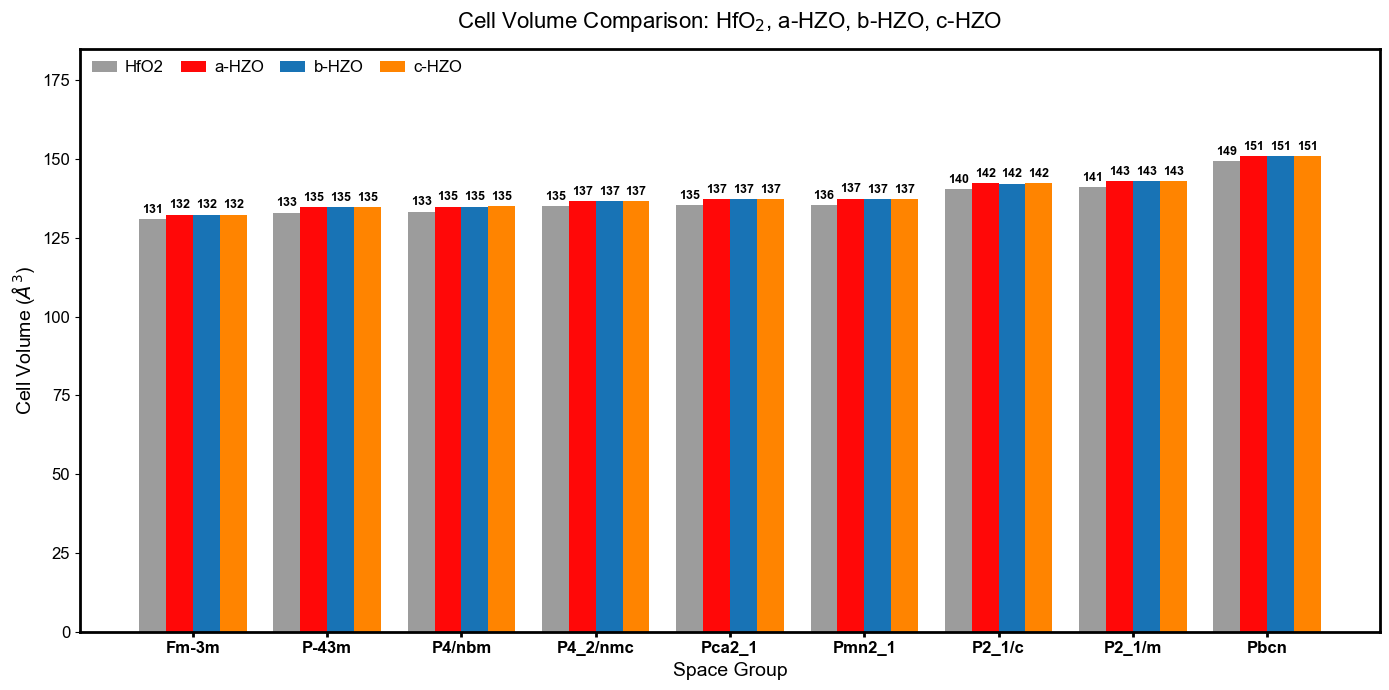

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 设置全局字体
matplotlib.rcParams['font.family'] = 'Arial'

def calc_cell_volume(a, b, c, alpha, beta, gamma):
    """
    根据晶格常数 (a, b, c) 和 角度 (alpha, beta, gamma) 计算晶胞体积。
    角度单位为度 (degrees)。
    """
    # 将角度转换为弧度
    alpha_r, beta_r, gamma_r = np.radians([alpha, beta, gamma])

    # 体积计算公式
    volume = a * b * c * np.sqrt(
        1 - np.cos(alpha_r)**2 - np.cos(beta_r)**2 - np.cos(gamma_r)**2 + 
        2 * np.cos(alpha_r) * np.cos(beta_r) * np.cos(gamma_r)
    )
    return volume

def plot_volume_chart(csv_file):
    # 1. 读取数据
    try:
        df = pd.read_csv(csv_file)
    except FileNotFoundError:
        print(f"Error: File {csv_file} not found.")
        return

    # 2. 定义需要计算体积的体系 (Methods) 以及对应的绘图配置
    # 顺序：HfO2 -> a-HZO -> b-HZO -> c-HZO
    methods_config = [
        {'name': 'HfO2',  'color': '#9c9c9c', 'label': 'HfO2'},
        {'name': 'a-HZO', 'color': '#ff0808', 'label': 'a-HZO'},
        {'name': 'b-HZO', 'color': '#1873b5', 'label': 'b-HZO'},
        {'name': 'c-HZO', 'color': '#ff8400', 'label': 'c-HZO'}
    ]

    # 3. 计算体积并添加到 DataFrame
    for config in methods_config:
        method = config['name']
        # 检查必要的列是否存在
        required_cols = [f"{method} {x}" for x in ['a', 'b', 'c', 'alpha', 'beta', 'gamma']]
        if all(col in df.columns for col in required_cols):
            df[f"{method}"] = df.apply(lambda row: calc_cell_volume(
                row[f"{method} a"], row[f"{method} b"], row[f"{method} c"],
                row[f"{method} alpha"], row[f"{method} beta"], row[f"{method} gamma"]
            ), axis=1)
        else:
            print(f"Warning: Columns for {method} not found. Skipping volume calculation for this method.")
            df[f"{method}"] = 0

    # 4. 排序 (Sort)
    # 你原来的代码是按 HfO2 Volume 排序，这会改变 X 轴 Space Group 的顺序
    # 如果希望和能量图保持 X 轴一致，可以注释掉这行；如果希望按体积大小排列，保留这行。
    # 这里默认保留你的逻辑：
    if "HfO2" in df.columns:
        df = df.sort_values(by="HfO2")

    # 保存包含体积数据的 CSV
    output_cols = ["Space Group"] + [f"{m['name']}" for m in methods_config]
    # 过滤掉不存在的列
    output_cols = [c for c in output_cols if c in df.columns]
    df.to_csv('structure_data_with_volumes_of_different_partial_doping.csv', index=False, columns=output_cols)
    print("Volume data saved to structure_data_with_volumes_of_different_partial_doping.csv")

    # 5. 绘图设置
    x_labels = df['Space Group']
    x = np.arange(len(x_labels))
    
    total_width = 0.8
    n_bars = len(methods_config)
    bar_width = total_width / n_bars

    fig, ax = plt.subplots(figsize=(14, 7))
    
    bars_list = []

    # 6. 循环绘制柱状图
    for i, config in enumerate(methods_config):
        method = config['name']
        col_name = f"{method}"
        
        if col_name in df.columns:
            vol_data = df[col_name]
            
            # 计算偏移量以居中
            offset = (i - (n_bars - 1) / 2) * bar_width
            
            bar = ax.bar(
                x + offset, 
                vol_data, 
                width=bar_width, 
                label=config['label'], 
                color=config['color'],
                # edgecolor='black',
                linewidth=0.5
            )
            bars_list.append(bar)

    # 7. 添加数值标签
    def add_value_labels(bars):
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height + 1,  # 稍微调高一点，避免紧贴
                    f"{height:.0f}", # 保留一位小数，体积通常不需要取整
                    ha='center', va='bottom', fontsize=9, color='black', rotation=0,
                    fontweight='bold'
                )

    for bars in bars_list:
        add_value_labels(bars)

    # 8. 设置坐标轴和图例
    ax.set_xlabel('Space Group', fontsize=14)
    ax.set_ylabel(r'Cell Volume ($\AA^3$)', fontsize=14)
    ax.set_ylim(0, 185)
    # 使用 LaTeX 格式优化标题
    ax.set_title(r'Cell Volume Comparison: HfO$_2$, a-HZO, b-HZO, c-HZO', fontsize=16, pad=15)
    
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, rotation=0, fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=12)
    ax.tick_params(axis='x', width=2)
    
    # 设置 Y 轴范围，使图表更美观（可选，因为体积通常在100以上，从0开始可能导致柱子差异不明显）
    # 如果想突出差异，可以设置 ylim。如果想看总量，保留默认从0开始。
    # ax.set_ylim(bottom=100) 

    for spine in ax.spines.values():
        spine.set_linewidth(2)

    ax.legend(
        fontsize=12,
        loc='upper left',
        bbox_to_anchor=(0.0, 1.0),
        frameon=False,
        ncol=4,
        handlelength=1.5,   # 图例线条长度（默认 2.0）
        handletextpad=0.5,  # 线条和文字之间的间距（默认 0.8）
        columnspacing=1,  # 列之间的间距（默认 2.0）
        labelspacing=0.3,   # 不同行之间的间距（默认 0.5）
        borderpad=0.2       # 图例边框与内容的间距（默认 0.4）
    )
    # ax.legend(fontsize=12, 
    #           loc='upper left', 
    #           bbox_to_anchor=(0.0, 1.0), 
    #           frameon=False, 
    #           ncol=4)
    ax.grid(False)
    
    plt.tight_layout()
    plt.savefig('cell_volume_comparison.png', dpi=300, bbox_inches='tight')
    print("Chart saved to cell_volume_comparison.png")
    plt.show()

# 运行
file_path = 'different_partial_doping_structure_data_grouped_ copy.csv'
plot_volume_chart(file_path)

<>:95: SyntaxWarning: invalid escape sequence '\A'
<>:110: SyntaxWarning: invalid escape sequence '\A'
<>:95: SyntaxWarning: invalid escape sequence '\A'
<>:110: SyntaxWarning: invalid escape sequence '\A'
C:\Users\23210\AppData\Local\Temp\ipykernel_27016\919085862.py:95: SyntaxWarning: invalid escape sequence '\A'
  f'{height:.2f} $\AA^3$', ha='center', va='bottom', fontsize=12)
C:\Users\23210\AppData\Local\Temp\ipykernel_27016\919085862.py:110: SyntaxWarning: invalid escape sequence '\A'
  ax2.set_ylabel('Unit Cell Volume ($\AA^3$)', fontsize=12)


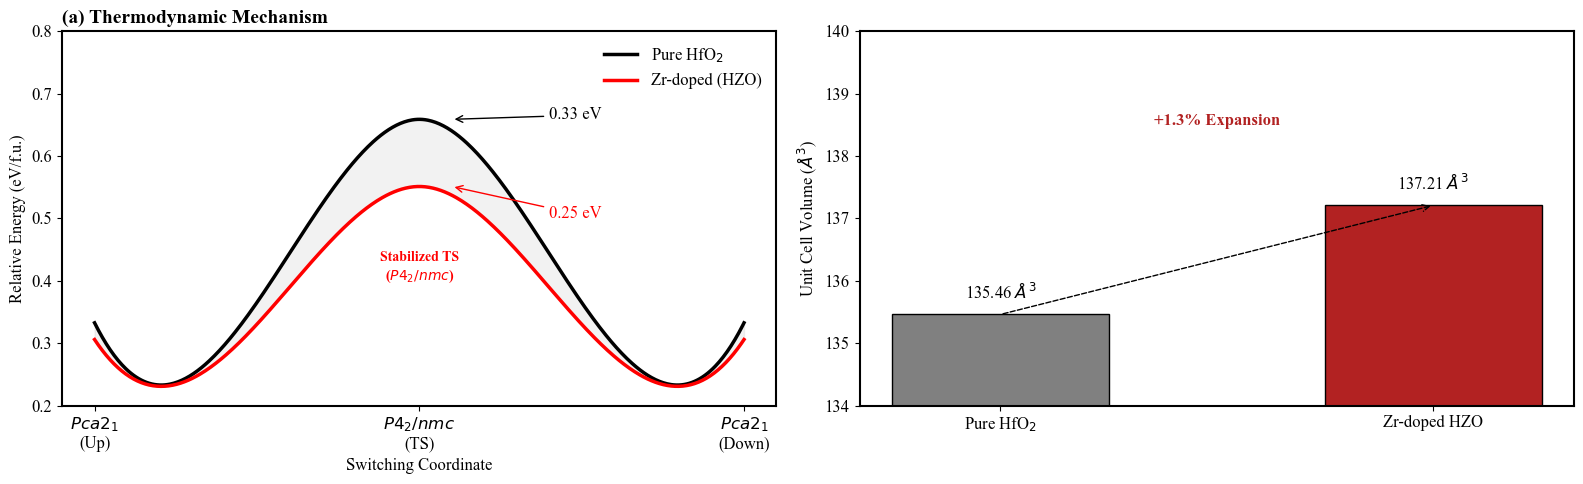

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# ==========================================
# 1. 数据准备 (基于你提供的计算数据)
# ==========================================

# 纯 HfO2 数据
hfo2_ground = 0.3326  # Pca2_1
hfo2_ts = 0.6589      # P4_2/nmc (Transition State)
hfo2_barrier = hfo2_ts - hfo2_ground
hfo2_vol = 135.46     # Volume

# c-HZO 数据 (以 c-HZO 为代表)
hzo_ground = 0.3058   # Pca2_1
hzo_ts = 0.5512       # P4_2/nmc (Transition State)
hzo_barrier = hzo_ts - hzo_ground
hzo_vol = 137.21      # Volume

# ==========================================
# 2. 绘图设置 (PRB 风格)
# ==========================================
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
plt.subplots_adjust(wspace=0.3)

# ==========================================
# 3. 左图：能量景观 (Energy Landscape)
# ==========================================

# 构建平滑曲线函数
def get_smooth_curve(y_ground, y_ts):
    x = np.array([-1, -0.5, 0, 0.5, 1])
    # 为了视觉美观，双势阱在两端稍微平缓一些
    y = np.array([y_ground, y_ground + (y_ts-y_ground)*0.1, y_ts, y_ground + (y_ts-y_ground)*0.1, y_ground])
    
    # 使用样条插值生成平滑曲线
    X_Y_Spline = make_interp_spline(x, y)
    X_ = np.linspace(-1, 1, 500)
    Y_ = X_Y_Spline(X_)
    return X_, Y_

# 绘制 HfO2 曲线
x_Hf, y_Hf = get_smooth_curve(hfo2_ground, hfo2_ts)
ax1.plot(x_Hf, y_Hf, 'k-', linewidth=2.5, label='Pure HfO$_2$')

# 绘制 HZO 曲线
x_Zr, y_Zr = get_smooth_curve(hzo_ground, hzo_ts)
ax1.plot(x_Zr, y_Zr, 'r-', linewidth=2.5, label='Zr-doped (HZO)')

# 填充势垒差异区域 (Highlight mechanism)
ax1.fill_between(x_Hf, y_Hf, y_Zr, where=(y_Hf > y_Zr), color='gray', alpha=0.1)

# 标注势垒高度
# HfO2 Arrow
ax1.annotate(f'{hfo2_barrier:.2f} eV', xy=(0.1, hfo2_ts), xytext=(0.4, hfo2_ts),
             arrowprops=dict(arrowstyle='->', color='black'), color='black')
# HZO Arrow
ax1.annotate(f'{hzo_barrier:.2f} eV', xy=(0.1, hzo_ts), xytext=(0.4, hzo_ts-0.05),
             arrowprops=dict(arrowstyle='->', color='red'), color='red')

# 核心机制标注
ax1.text(0, hzo_ts - 0.15, "Stabilized TS\n($P4_2/nmc$)", ha='center', color='red', fontsize=10, fontweight='bold')

# 设置轴标签
ax1.set_ylabel('Relative Energy (eV/f.u.)', fontsize=12)
ax1.set_xlabel('Switching Coordinate', fontsize=12)
ax1.set_title('(a) Thermodynamic Mechanism', loc='left', fontsize=14, fontweight='bold')
ax1.set_xticks([-1, 0, 1])
ax1.set_xticklabels(['$Pca2_1$\n(Up)', '$P4_2/nmc$\n(TS)', '$Pca2_1$\n(Down)'])
ax1.legend(frameon=False)
ax1.set_ylim(0.2, 0.8)

# ==========================================
# 4. 右图：几何体积膨胀 (Volume Expansion)
# ==========================================

# 数据
labels = ['Pure HfO$_2$', 'Zr-doped HZO']
values = [hfo2_vol, hzo_vol]
colors = ['gray', 'firebrick']

# 绘制柱状图
bars = ax2.bar(labels, values, color=colors, width=0.5, edgecolor='black')

# 在柱子上标注数值
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.2,
             f'{height:.2f} $\AA^3$', ha='center', va='bottom', fontsize=12)

# 计算膨胀百分比
expansion = ((hzo_vol - hfo2_vol) / hfo2_vol) * 100
ax2.text(0.5, 138.5, f"+{expansion:.1f}% Expansion", ha='center', fontsize=12, color='firebrick', fontweight='bold')

# 绘制示意箭头
ax2.annotate("", xy=(1, hzo_vol), xytext=(0, hfo2_vol),
             arrowprops=dict(arrowstyle="->", linestyle="dashed", color="black"))

# 核心机制说明
# ax2.text(0.5, 136, "Larger Volume\n=\nReduced Steric\nHindrance", 
#          ha='center', va='center', bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))

# 设置轴标签
ax2.set_ylabel('Unit Cell Volume ($\AA^3$)', fontsize=12)
ax2.set_title(' ', loc='left', fontsize=14, fontweight='bold')
ax2.set_ylim(134, 140) # 聚焦于顶部变化

# ==========================================
# 5. 保存与展示
# ==========================================
plt.tight_layout()
plt.show()

# 如果你在本地运行，可以取消下面这行的注释来保存图片
# plt.savefig('HZO_Mechanism_PRB.png', dpi=300)